# COMS4060A/7056A – Assignment 2: Geospatial & Time-Series Analysis of NYC Taxi Trips

**Dataset:** NYC TLC taxi trips (Kaggle *nyc-taxi-trip-duration*), `train.csv` only – 1 458 644 trips, 2016-01-01 → 2016-06-30.
**Deadline:** 28 October 2026 · **Total marks:** 63

This single notebook answers every question; each section header carries the question number.
Reasoning that goes in the NeurIPS-style PDF is repeated here in the markdown cells so the two stay in sync.

| Section | Topic | Marks |
|---|---|---|
| 0 | Setup & data loading | – |
| 1 | Data cleaning | 3 |
| 2 | Feature generation | 3 |
| 3 | Time-based analysis | 14 |
| 4 | Location clusters (heatmaps, DBSCAN hotspots) | 12 |
| 5 | Airports | 9 |
| 6 | Dimensionality reduction (PCA / t-SNE / UMAP) | 22 |

> **Progress:** Sections 0–3 are complete. Sections 4–6 are placeholders that will be filled in sequentially.

## 0. Setup & data loading

All random operations use the fixed seed `SEED = 42` for reproducibility.
The loader looks for `train.csv` in a few places and, if it is absent, reads it straight out of the
`nyc-taxi-trip-duration.zip` that sits in the repository (the zip contains a nested `train.zip`).

In [1]:
import os, io, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold"})

FIG_DIR = "figures"            # every figure used in the PDF is also saved here
os.makedirs(FIG_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight")

# --- constants given in the assignment ---------------------------------------------------
NYC_CENTRE = (40.716662, -74.009899)           # (lat, lon) as given in the brief

In [2]:
def load_train():
    """Load train.csv from disk, or straight out of the nested zip files in the repo."""
    kw = dict(parse_dates=["pickup_datetime", "dropoff_datetime"])
    for p in ["train.csv", "data/train.csv", "/tmp/claude-0/data/raw/train.csv"]:
        if os.path.exists(p):
            return pd.read_csv(p, **kw)
    with zipfile.ZipFile("nyc-taxi-trip-duration.zip") as outer:
        inner = zipfile.ZipFile(io.BytesIO(outer.read("train.zip")))
        with inner.open("train.csv") as f:
            return pd.read_csv(f, **kw)

raw = load_train()
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
raw.head()

Rows: 1,458,644   Columns: 11


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [3]:
print(raw.dtypes, end="\n\n")
print("Missing values per column:\n", raw.isna().sum().to_string(), sep="")
print("\nDuplicate trip ids:", raw["id"].duplicated().sum())
print("Date range:", raw["pickup_datetime"].min(), "→", raw["pickup_datetime"].max())
# does trip_duration agree with dropoff - pickup?
gap = (raw["dropoff_datetime"] - raw["pickup_datetime"]).dt.total_seconds() - raw["trip_duration"]
print("Rows where trip_duration != dropoff - pickup:", int((gap != 0).sum()))
raw.describe().T

id                               str
vendor_id                      int64
pickup_datetime       datetime64[us]
dropoff_datetime      datetime64[us]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag               str
trip_duration                  int64
dtype: object

Missing values per column:
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0



Duplicate trip ids: 0
Date range: 2016-01-01 00:00:17 → 2016-06-30 23:59:39
Rows where trip_duration != dropoff - pickup: 0


,count,mean,min,25%,50%,75%,max,std
vendor_id,1458644.0,1.53495,1.0,1.0,2.0,2.0,2.0,0.498777
pickup_datetime,1458644,2016-04-01 10:10:24.940038,2016-01-01 00:00:17,2016-02-17 16:46:04.250000,2016-04-01 17:19:40,2016-05-15 03:56:08.750000,2016-06-30 23:59:39,NaN
dropoff_datetime,1458644,2016-04-01 10:26:24.432309,2016-01-01 00:03:31,2016-02-17 17:05:32.500000,2016-04-01 17:35:12,2016-05-15 04:10:51.750000,2016-07-01 23:02:03,NaN
passenger_count,1458644.0,1.66453,0.0,1.0,1.0,2.0,9.0,1.314242
pickup_longitude,1458644.0,-73.973486,-121.933342,-73.991867,-73.981743,-73.967331,-61.335529,0.070902
pickup_latitude,1458644.0,40.750921,34.359695,40.737347,40.754101,40.76836,51.881084,0.032881
dropoff_longitude,1458644.0,-73.973416,-121.933304,-73.991325,-73.979752,-73.963013,-61.335529,0.070643
dropoff_latitude,1458644.0,40.7518,32.181141,40.735885,40.754524,40.76981,43.921028,0.035891
trip_duration,1458644.0,959.492273,1.0,397.0,662.0,1075.0,3526282.0,5237.431724


**Initial data audit.** There are no missing values and no duplicate ids, and `trip_duration` is exactly
`dropoff_datetime − pickup_datetime` for every row, so there is no timestamp inconsistency to repair.
The `describe()` table already shows the problem the assignment hints at: coordinates as far away as
longitude −121.9 / latitude 51.9 (not New York), passenger counts of 0 and up to 9, a minimum duration of 1 s
and a maximum of 3 526 282 s (≈ 40 days). The following section quantifies and removes these.

---
## 1. Data Cleaning [3 marks]

**Goal:** identify outliers / impossible records and justify their removal.
We examine five aspects: (a) passenger count, (b) geographic location, (c) trip duration, (d) trip distance, (e) average speed.
Distance is the **great-circle (haversine) distance** between pickup and dropoff (formula supplied in the brief);
speed is `distance / duration`. These two derived columns are also required in Question 2.

> Note on haversine: it is a *lower bound* on the road distance actually driven (streets are not straight lines),
> so the speeds we compute under-estimate real speeds. Thresholds are therefore set generously.

In [4]:
def haversine_np(lon1, lat1, lon2, lat2):
    """Great-circle distance in km between points given in decimal degrees (vectorised)."""
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6367 * c

df = raw.copy()
df["distance_km"] = haversine_np(df.pickup_longitude, df.pickup_latitude,
                                 df.dropoff_longitude, df.dropoff_latitude)
df["speed_kmh"] = df["distance_km"] / (df["trip_duration"] / 3600.0)
df[["trip_duration", "distance_km", "speed_kmh"]].describe(percentiles=[.001, .01, .5, .99, .999]).T

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
trip_duration,1458644.0,959.492273,5237.431724,1.0,7.0,87.000000,662.000000,3440.000000,85128.357000,3.526282e+06
distance_km,1458644.0,3.438704,4.293840,0.0,0.0,0.138935,2.092403,20.774468,24.751208,1.240130e+03
speed_kmh,1458644.0,14.414153,14.968121,0.0,0.0,1.393366,12.783947,40.719722,54.267879,9.269014e+03


### 1.1 Passenger count

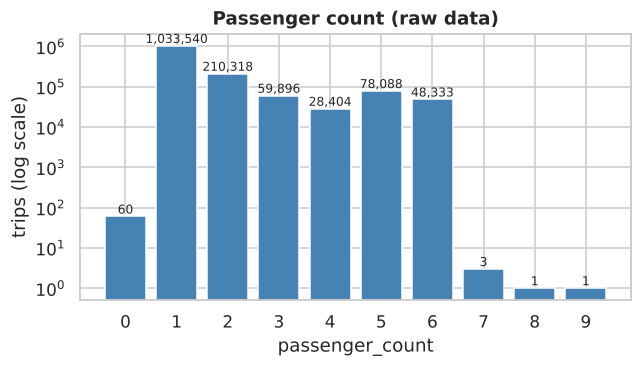

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))
vc = raw["passenger_count"].value_counts().sort_index()
ax.bar(vc.index.astype(str), vc.values, color="steelblue")
ax.set_yscale("log"); ax.set_xlabel("passenger_count"); ax.set_ylabel("trips (log scale)")
ax.set_title("Passenger count (raw data)")
for x, v in zip(vc.index.astype(str), vc.values): ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); savefig("q1_passenger_count"); plt.show()

**Reasoning.** Yellow-cab capacity in NYC is 4 passengers (5 for some vehicles; up to 6 for larger vans/minivans, which the data
shows are common: 78 088 trips with 5 and 48 333 with 6 passengers). Counts of **0** (60 trips) have no passenger so
cannot be a real paid trip, and **7, 8, 9** (5 trips in total) exceed the capacity of any taxi. These are data-entry errors
(the field is *driver entered*) so we keep only `1 ≤ passenger_count ≤ 6`.

### 1.2 Geographic outliers

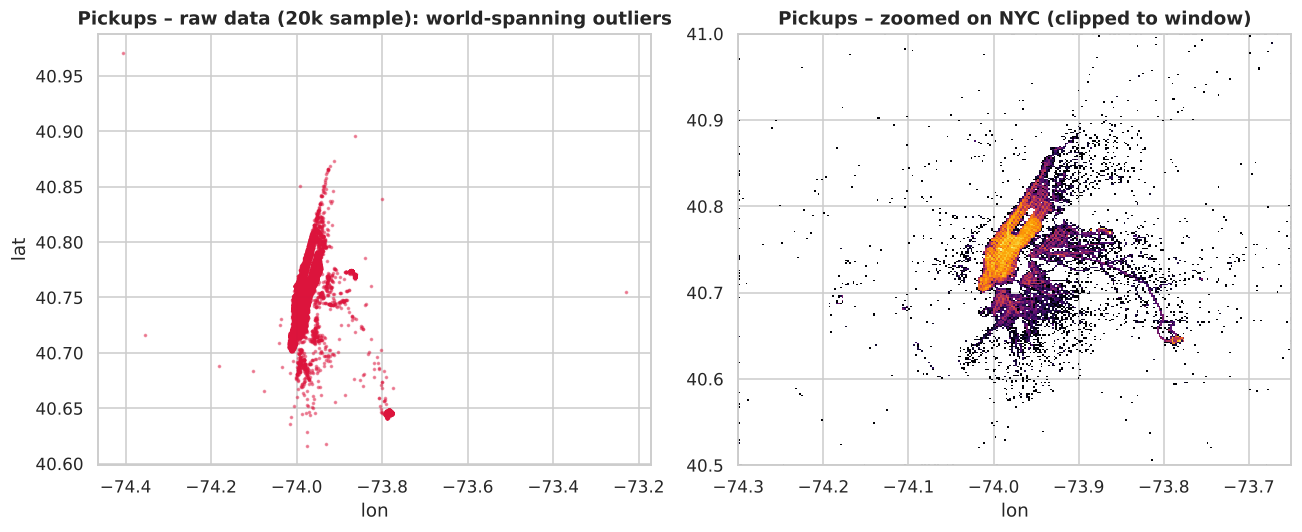

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(raw.pickup_longitude.sample(20000, random_state=SEED), raw.pickup_latitude.sample(20000, random_state=SEED),
                s=2, alpha=.4, color="crimson")
axes[0].set_title("Pickups – raw data (20k sample): world-spanning outliers"); axes[0].set_xlabel("lon"); axes[0].set_ylabel("lat")
h = axes[1].hist2d(raw.pickup_longitude.clip(-74.3, -73.65), raw.pickup_latitude.clip(40.5, 41.0),
                   bins=300, cmap="inferno", norm=plt.matplotlib.colors.LogNorm())
axes[1].set_title("Pickups – zoomed on NYC (clipped to window)"); axes[1].set_xlabel("lon")
plt.tight_layout(); savefig("q1_geo_raw"); plt.show()

In [7]:
# Bounding box that comfortably contains the five boroughs *and* both airports (JFK -73.78, Newark -74.17)
LON_MIN, LON_MAX = -74.30, -73.65
LAT_MIN, LAT_MAX = 40.49, 40.92
in_box = lambda lon, lat: lon.between(LON_MIN, LON_MAX) & lat.between(LAT_MIN, LAT_MAX)
geo_ok = in_box(df.pickup_longitude, df.pickup_latitude) & in_box(df.dropoff_longitude, df.dropoff_latitude)
print(f"Trips with pickup or dropoff outside the NYC window: {(~geo_ok).sum():,} ({(~geo_ok).mean():.3%})")
print("  of which both ends are outside:",
      int((~in_box(df.pickup_longitude, df.pickup_latitude) & ~in_box(df.dropoff_longitude, df.dropoff_latitude)).sum()))

Trips with pickup or dropoff outside the NYC window: 1,096 (0.075%)
  of which both ends are outside: 263


**Reasoning.** The dataset is *New York City* taxi data, yet the raw coordinates include points near longitude −121.9
(the US west coast), latitude 51.9 (Canada) and −61.3 (the Atlantic). These are GPS errors/zero-fixes, not real trips.
We keep trips whose pickup **and** dropoff both lie in the window lon ∈ [−74.30, −73.65], lat ∈ [40.49, 40.92], which
covers all five boroughs plus Newark (−74.17) and JFK (−73.78) airports (needed for Question 5). A point outside this
window cannot be reached by a taxi inside a few-hours trip, and would dominate every spatial analysis (heatmaps, DBSCAN, PCA scaling).

### 1.3 Trip duration

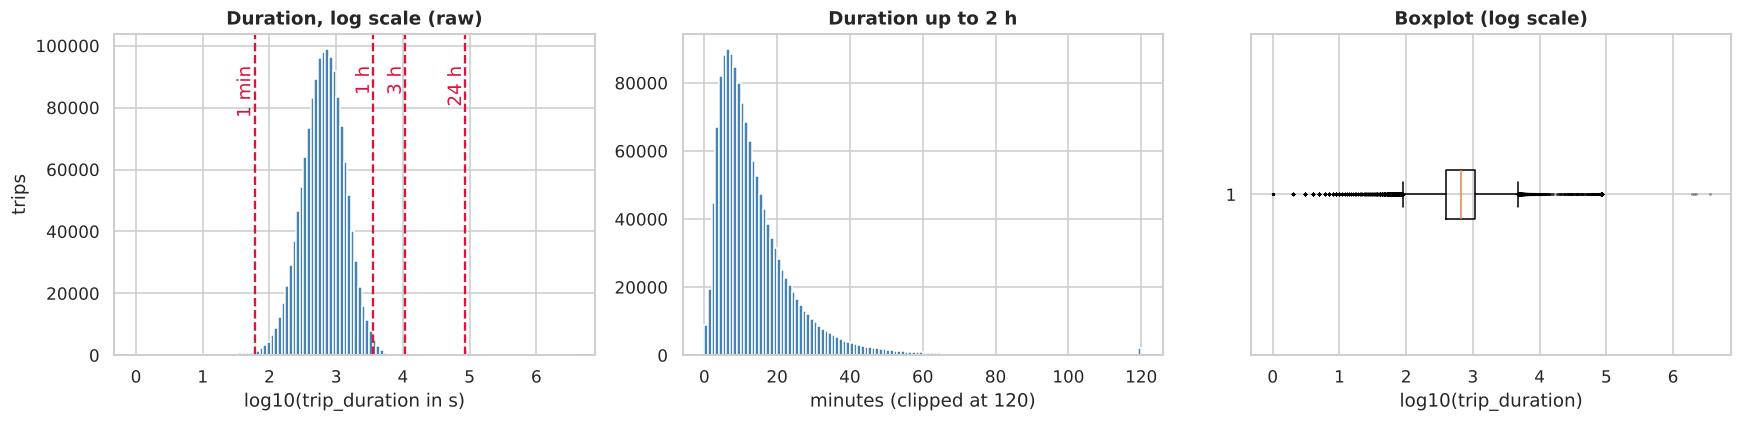

< 60 s : 8,595    < 10 s : 1,984
> 3 h  : 2,112    > 24 h : 4   max = 40.8 days


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(np.log10(raw.trip_duration), bins=120, color="steelblue")
axes[0].set_xlabel("log10(trip_duration in s)"); axes[0].set_ylabel("trips"); axes[0].set_title("Duration, log scale (raw)")
for v, l in [(60, "1 min"), (3600, "1 h"), (10800, "3 h"), (86400, "24 h")]:
    axes[0].axvline(np.log10(v), color="crimson", ls="--"); axes[0].text(np.log10(v), axes[0].get_ylim()[1]*.9, l, rotation=90, color="crimson", va="top", ha="right")
axes[1].hist(raw.trip_duration.clip(upper=7200)/60, bins=120, color="steelblue")
axes[1].set_xlabel("minutes (clipped at 120)"); axes[1].set_title("Duration up to 2 h")
axes[2].boxplot(np.log10(raw.trip_duration), vert=False, flierprops=dict(marker=".", markersize=2, alpha=.3))
axes[2].set_xlabel("log10(trip_duration)"); axes[2].set_title("Boxplot (log scale)")
plt.tight_layout(); savefig("q1_duration_raw"); plt.show()

dur = raw.trip_duration
print(f"< 60 s : {(dur<60).sum():,}    < 10 s : {(dur<10).sum():,}")
print(f"> 3 h  : {(dur>3*3600).sum():,}    > 24 h : {(dur>86400).sum():,}   max = {dur.max()/86400:.1f} days")

**Reasoning.** On a log scale the bulk of trips is a smooth, roughly log-normal bump centred at ≈ 11 min, with a thin
extreme tail on **both** sides:
* **Too short (< 60 s).** A cab cannot meaningfully hail, carry and drop a passenger in under a minute; these are
  accidental meter starts, cancelled rides or driver test records (8 595 trips are < 60 s, 1 984 of them < 10 s).
* **Too long (> 3 h).** Intra-city taxi trips essentially never last longer than a few hours; the tail contains trips of
  up to ≈ 40 days (meter left running/never switched off). 2 112 trips exceed 3 h and 4 exceed 24 h; they they distort every mean and
  every duration scaling. The 3 h cap is conservative: it exceeds the longest realistic NYC–airport journeys in heavy traffic.

### 1.4 Trip distance

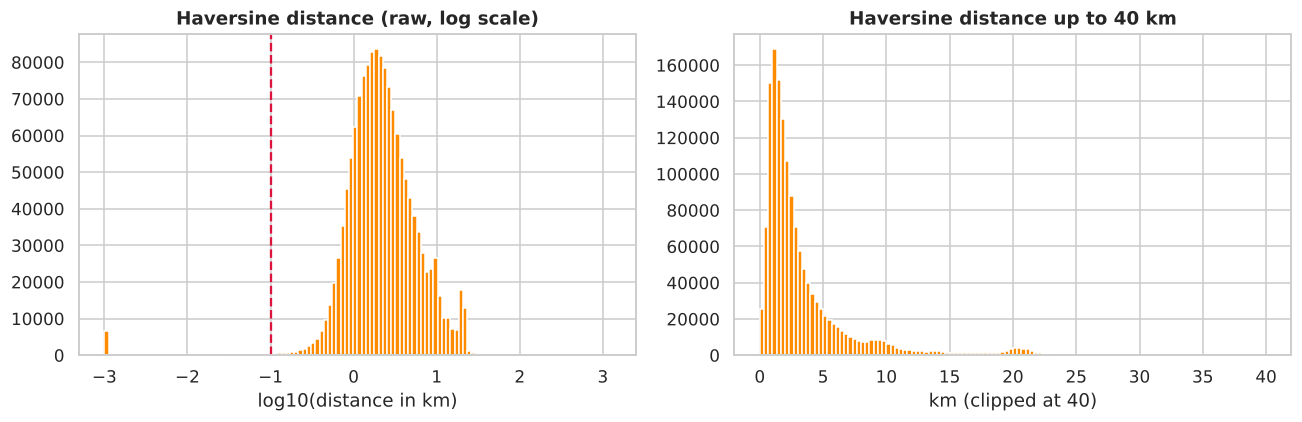

distance == 0 km: 5,897;  < 100 m: 13,319;  > 100 km: 19


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log10(df.distance_km.clip(lower=1e-3)), bins=120, color="darkorange")
axes[0].set_xlabel("log10(distance in km)"); axes[0].set_title("Haversine distance (raw, log scale)")
axes[0].axvline(np.log10(0.1), color="crimson", ls="--")
axes[1].hist(df.distance_km.clip(upper=40), bins=120, color="darkorange")
axes[1].set_xlabel("km (clipped at 40)"); axes[1].set_title("Haversine distance up to 40 km")
plt.tight_layout(); savefig("q1_distance_raw"); plt.show()
print(f"distance == 0 km: {(df.distance_km == 0).sum():,};  < 100 m: {(df.distance_km < .1).sum():,};  > 100 km: {(df.distance_km > 100).sum():,}")

**Reasoning.** A sizeable spike sits at ≈ 0 km: trips whose pickup and dropoff coordinates are (almost) identical.
Some of these are zero-length because the driver never really drove (cancelled fare) or the GPS failed; for the rest the
speed is meaningless (division by ~0). Trips shorter than **100 m** are below the typical GPS positioning error in
Manhattan's "urban canyon" (≈ 10-50 m), so a 100 m trip is indistinguishable from "didn't move" and cannot represent a
paid taxi fare. On the long side the largest legitimate distance inside our NYC window is below ≈ 50 km
(Newark ↔ the Bronx/Queens is the extreme), so no extra distance upper cap is needed beyond the geographic window and speed filter.

### 1.5 Average speed

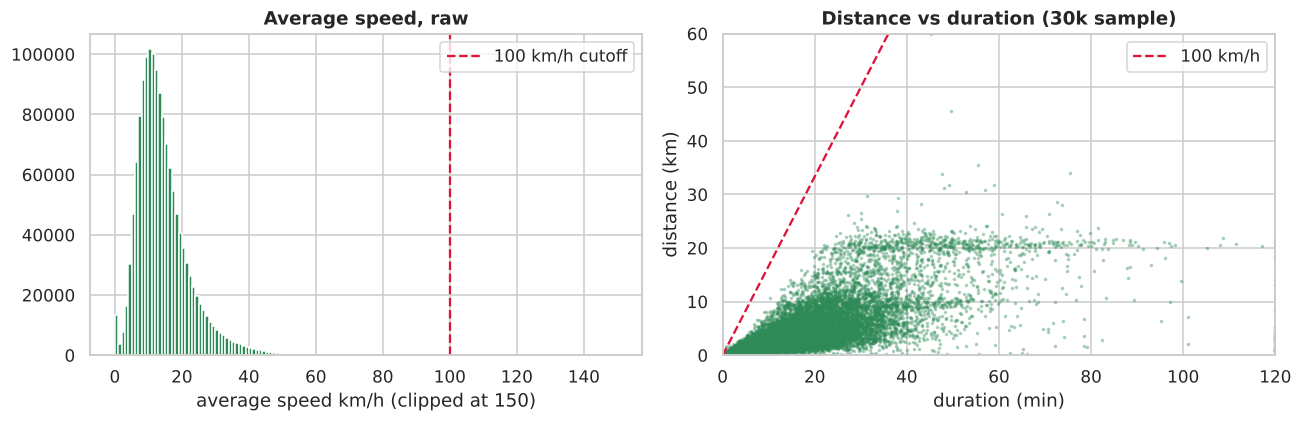

count    1458644.0
mean          14.4
std           15.0
min            0.0
50%           12.8
99%           40.7
99.9%         54.3
max         9269.0
> 100 km/h: 175   > 200 km/h: 68


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df.speed_kmh.clip(upper=150), bins=150, color="seagreen")
axes[0].axvline(100, color="crimson", ls="--", label="100 km/h cutoff"); axes[0].legend()
axes[0].set_xlabel("average speed km/h (clipped at 150)"); axes[0].set_title("Average speed, raw")
axes[1].scatter(df.sample(30000, random_state=SEED).trip_duration.clip(upper=7200)/60,
                df.sample(30000, random_state=SEED).distance_km.clip(upper=60), s=2, alpha=.3, color="seagreen")
for sp, ls in [(100, "--")]:
    x = np.linspace(0, 120, 100); axes[1].plot(x, sp * x / 60, "crimson", ls=ls, label="100 km/h")
axes[1].set_ylim(0, 60); axes[1].set_xlim(0, 120); axes[1].legend()
axes[1].set_xlabel("duration (min)"); axes[1].set_ylabel("distance (km)"); axes[1].set_title("Distance vs duration (30k sample)")
plt.tight_layout(); savefig("q1_speed_raw"); plt.show()
print(df.speed_kmh.describe(percentiles=[.5, .99, .999]).round(1).to_string())
print(f"> 100 km/h: {(df.speed_kmh > 100).sum():,}   > 200 km/h: {(df.speed_kmh > 200).sum():,}")

**Reasoning.** The speed distribution of genuine trips is a right-skewed bell with median ≈ 13 km/h (heavy Manhattan traffic) and a
long right tail. A tail of absurd values (hundreds to thousands of km/h) exists, produced by trips whose recorded
duration is a few seconds but whose coordinates are kilometres apart. The posted speed limits are 25 mph (40 km/h) in the
city and ≤ 65 mph (105 km/h) on highways; as haversine under-estimates road distance, any trip with an *average*
speed over **100 km/h** is physically implausible. We also remove trips below the minimum realistic speed
(see below) because they are trips that were open for a long time with very little movement (waiting taxis, forgotten meters).

3322 trips with average speed < 1 km/h  (walking pace is ~5 km/h)


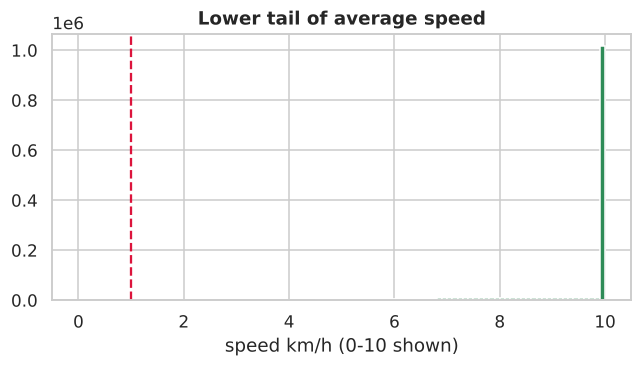

In [11]:
# very slow trips: show the lower tail of speed for trips that moved at least 100 m
slow = df[(df.distance_km >= .1)]
print((slow.speed_kmh < 1).sum(), "trips with average speed < 1 km/h  (walking pace is ~5 km/h)")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(slow.speed_kmh.clip(upper=10), bins=100, color="seagreen"); ax.axvline(1, color="crimson", ls="--")
ax.set_xlabel("speed km/h (0-10 shown)"); ax.set_title("Lower tail of average speed"); plt.tight_layout(); savefig("q1_speed_low"); plt.show()

Trips averaging **< 1 km/h** are slower than walking (~5 km/h) over the entire trip: the vehicle was effectively
stationary with the meter running, so these are not representative trips and are removed.

### 1.6 Applying the filters – cleaning funnel

In [12]:
rules = {
    "passenger_count not in [1, 6]":             ~df.passenger_count.between(1, 6),
    "coordinates outside NYC window":            ~geo_ok,
    "duration < 60 s":                           df.trip_duration < 60,
    "duration > 3 h":                            df.trip_duration > 3 * 3600,
    "distance < 100 m":                          df.distance_km < 0.1,
    "average speed > 100 km/h":                  df.speed_kmh > 100,
    "average speed < 1 km/h":                    df.speed_kmh < 1,
}
rows, remaining = [], pd.Series(True, index=df.index)
for name, bad in rules.items():
    newly = bad & remaining
    rows.append({"rule": name, "flagged_alone": int(bad.sum()), "newly_removed_in_order": int(newly.sum())})
    remaining &= ~bad
funnel = pd.DataFrame(rows)
funnel["flagged_alone_%"] = (funnel.flagged_alone / len(df) * 100).round(3)
print(f"Original: {len(df):,}   Kept: {remaining.sum():,}   Removed: {(~remaining).sum():,} ({(~remaining).mean():.2%})")
funnel

Original: 1,458,644   Kept: 1,438,196   Removed: 20,448 (1.40%)


,rule,flagged_alone,newly_removed_in_order,flagged_alone_%
0,"passenger_count not in [1, 6]",65,65,0.004
1,coordinates outside NYC window,1096,1095,0.075
2,duration < 60 s,8595,8401,0.589
3,duration > 3 h,2112,2104,0.145
4,distance < 100 m,13319,7442,0.913
5,average speed > 100 km/h,175,33,0.012
6,average speed < 1 km/h,13241,1308,0.908


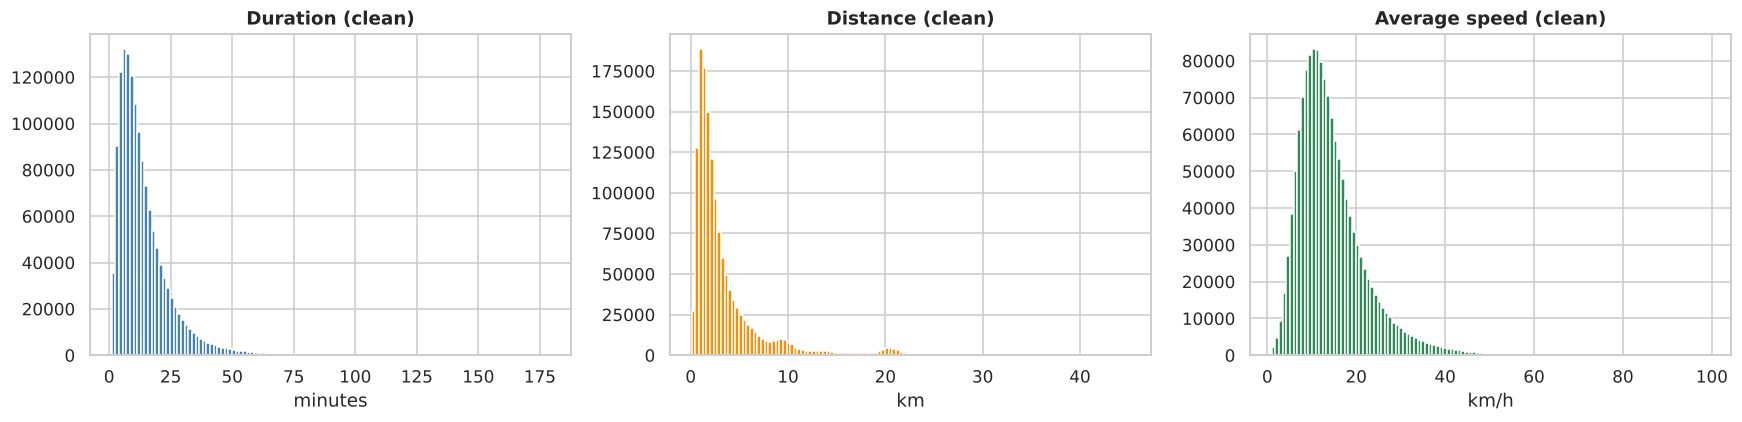

,count,mean,std,min,1%,50%,99%,max
passenger_count,1438196.0,1.67,1.31,1.0,1.00,1.00,6.00,6.00
trip_duration,1438196.0,840.43,653.08,60.0,112.00,665.00,3301.00,10731.00
distance_km,1438196.0,3.46,3.88,0.1,0.39,2.12,20.73,45.08
speed_kmh,1438196.0,14.47,7.59,1.0,3.34,12.85,40.33,99.47


In [13]:
clean = df[remaining].reset_index(drop=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(clean.trip_duration / 60, bins=120, color="steelblue"); axes[0].set_xlabel("minutes"); axes[0].set_title("Duration (clean)")
axes[1].hist(clean.distance_km, bins=120, color="darkorange"); axes[1].set_xlabel("km"); axes[1].set_title("Distance (clean)")
axes[2].hist(clean.speed_kmh, bins=120, color="seagreen"); axes[2].set_xlabel("km/h"); axes[2].set_title("Average speed (clean)")
plt.tight_layout(); savefig("q1_clean_distributions"); plt.show()

clean[["passenger_count", "trip_duration", "distance_km", "speed_kmh"]].describe(percentiles=[.01, .5, .99]).T.round(2)

### Summary of Question 1

| Rule | Justification |
|---|---|
| `passenger_count ∉ [1, 6]` | 0 passengers = no fare; 7–9 exceed any taxi's capacity → data-entry errors |
| pickup/dropoff outside lon [−74.30, −73.65], lat [40.49, 40.92] | not in NYC (coordinates in Atlantic, Canada, west coast); window still includes JFK and Newark |
| duration < 60 s | cancelled/accidental meter start, no real journey |
| duration > 3 h | meter left running; up to ≈ 40 days; unrealistic intra-city trip |
| distance < 100 m | below GPS accuracy – trip did not go anywhere; speed undefined |
| speed > 100 km/h | physically impossible for the *average* of a city trip given haversine under-estimates distance |
| speed < 1 km/h | slower than walking over the whole trip → stationary vehicle with meter running |

The filters remove only about 1.4 % of the data (20 448 of 1 458 644 trips) (see funnel), so the cleaned data set is still essentially the full
sample, while mean-based statistics, scalers and distance-based methods (DBSCAN, t-SNE, UMAP) are no longer dominated by errors.
The table above shows how many trips each rule flagged on its own and how many it removed in sequence (rules overlap).

---
## 2. Feature generation [3 marks]

Required: **trip distance**, **day of week**, **average speed**. We add further features that are used in later sections.
Features are built on the *cleaned* data (the order is irrelevant to the result; distance and speed were already
computed above to drive the cleaning, and are re-derived here from scratch so this section stands alone).

In [14]:
feat = clean.copy()

# ---- required features --------------------------------------------------------------------
feat["distance_km"] = haversine_np(feat.pickup_longitude, feat.pickup_latitude,
                                   feat.dropoff_longitude, feat.dropoff_latitude)          # 1. distance of trip
feat["speed_kmh"] = feat["distance_km"] / (feat["trip_duration"] / 3600.0)                  # 3. average speed of trip
feat["day_of_week"] = feat.pickup_datetime.dt.dayofweek                                     # 2. day of week (0=Mon … 6=Sun)
feat["day_name"] = pd.Categorical(feat.pickup_datetime.dt.day_name(),
                                  categories=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
                                  ordered=True)

# ---- extra features -------------------------------------------------------------------------
feat["pickup_hour"] = feat.pickup_datetime.dt.hour
feat["pickup_date"] = feat.pickup_datetime.dt.normalize()
feat["pickup_month"] = feat.pickup_datetime.dt.month
feat["is_weekend"] = feat.day_of_week >= 5
feat["duration_min"] = feat.trip_duration / 60.0
feat["hour_sin"] = np.sin(2 * np.pi * feat.pickup_hour / 24)      # cyclic hour encoding, used in Q6
feat["hour_cos"] = np.cos(2 * np.pi * feat.pickup_hour / 24)
# Manhattan-style (L1) distance: grid streets mean the real route is closer to |dlat|+|dlon| than to the straight line
feat["manhattan_km"] = (haversine_np(feat.pickup_longitude, feat.pickup_latitude, feat.dropoff_longitude, feat.pickup_latitude)
                      + haversine_np(feat.dropoff_longitude, feat.pickup_latitude, feat.dropoff_longitude, feat.dropoff_latitude))
# initial compass bearing (degrees, 0=north): captures the dominant direction of travel on the Manhattan grid
dlon = np.radians(feat.dropoff_longitude - feat.pickup_longitude)
la1, la2 = np.radians(feat.pickup_latitude), np.radians(feat.dropoff_latitude)
feat["bearing_deg"] = (np.degrees(np.arctan2(np.sin(dlon) * np.cos(la2),
                        np.cos(la1) * np.sin(la2) - np.sin(la1) * np.cos(la2) * np.cos(dlon))) + 360) % 360
# distances to the city centre given in the brief
feat["pickup_dist_centre_km"] = haversine_np(feat.pickup_longitude, feat.pickup_latitude, NYC_CENTRE[1], NYC_CENTRE[0])
feat["dropoff_dist_centre_km"] = haversine_np(feat.dropoff_longitude, feat.dropoff_latitude, NYC_CENTRE[1], NYC_CENTRE[0])

new_cols = ["distance_km", "speed_kmh", "day_of_week", "day_name", "pickup_hour", "pickup_date", "pickup_month", "is_weekend",
            "duration_min", "hour_sin", "hour_cos", "manhattan_km", "bearing_deg", "pickup_dist_centre_km", "dropoff_dist_centre_km"]
print(f"Clean trips: {len(feat):,}   |   new feature columns: {len(new_cols)}")
feat[["pickup_datetime", "trip_duration"] + new_cols].head()

Clean trips: 1,438,196   |   new feature columns: 15


,pickup_datetime,trip_duration,distance_km,speed_kmh,day_of_week,day_name,pickup_hour,pickup_date,pickup_month,is_weekend,duration_min,hour_sin,hour_cos,manhattan_km,bearing_deg,pickup_dist_centre_km,dropoff_dist_centre_km
0,2016-03-14 17:24:55,455,1.497580,11.848984,0,Monday,17,2016-03-14,3,False,7.583333,-0.965926,-0.258819,1.734344,99.970196,6.158130,6.641094
1,2016-06-12 00:43:35,663,1.804374,9.797504,6,Sunday,0,2016-06-12,6,True,11.050000,0.000000,1.000000,2.428980,242.846232,3.476814,1.833676
2,2016-01-19 11:35:24,2124,6.381090,10.815406,1,Tuesday,11,2016-01-19,1,False,35.400000,0.258819,-0.965926,8.198424,200.319835,5.861520,0.825708
3,2016-04-06 19:32:31,429,1.484566,12.457894,2,Wednesday,19,2016-04-06,4,False,7.150000,-0.965926,0.258819,1.660288,187.262300,0.367873,1.122853
4,2016-03-26 13:30:55,435,1.187842,9.830418,5,Saturday,13,2016-03-26,3,True,7.250000,-0.258819,-0.965926,1.198704,179.473585,9.054132,7.952995


In [15]:
feat[["distance_km", "speed_kmh", "duration_min", "manhattan_km", "pickup_dist_centre_km", "dropoff_dist_centre_km"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
distance_km,1438196.0,3.46,3.88,0.10,1.26,2.12,3.90,45.08
speed_kmh,1438196.0,14.47,7.59,1.00,9.23,12.85,17.87,99.47
duration_min,1438196.0,14.01,10.88,1.00,6.70,11.08,17.92,178.85
manhattan_km,1438196.0,4.47,5.16,0.10,1.60,2.72,5.04,61.92
pickup_dist_centre_km,1438196.0,5.52,3.60,0.01,3.10,5.02,7.14,31.21
dropoff_dist_centre_km,1438196.0,5.74,3.55,0.00,3.34,5.25,7.50,33.40


Median Manhattan/straight-line ratio: 1.327


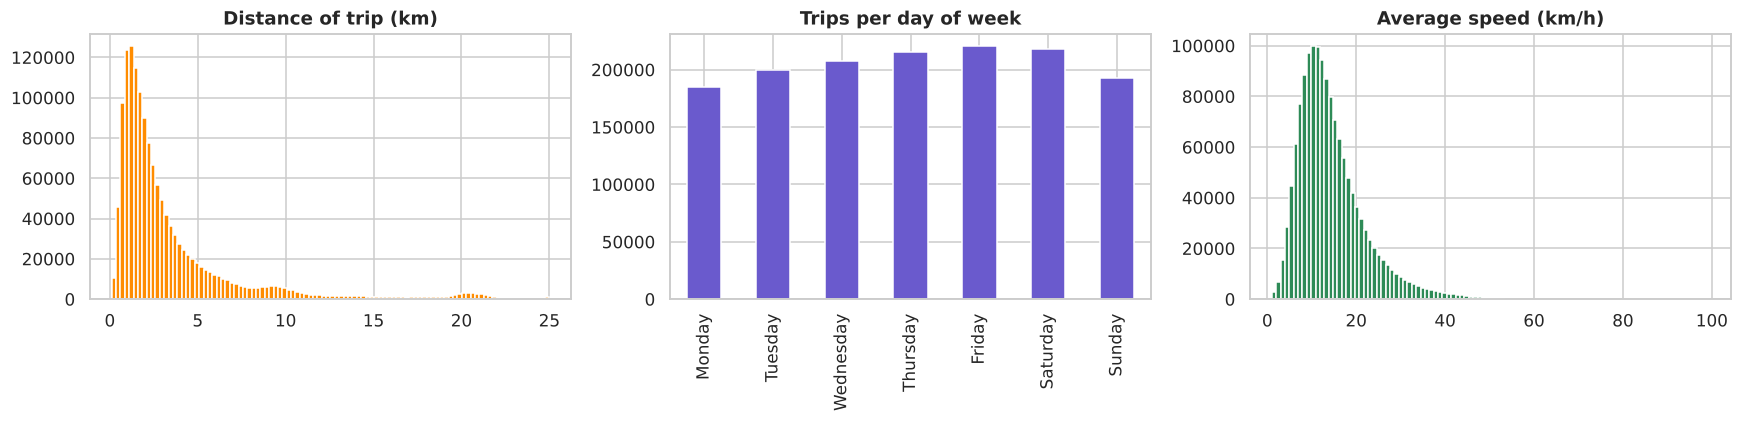

In [16]:
# Sanity checks on the generated features
assert feat.day_of_week.between(0, 6).all() and feat.pickup_hour.between(0, 23).all()
assert (feat.distance_km > 0).all() and (feat.speed_kmh > 0).all()
assert (feat.manhattan_km >= feat.distance_km - 1e-9).all()     # L1 route can never be shorter than the straight line
assert np.allclose(feat.hour_sin**2 + feat.hour_cos**2, 1)
print("Median Manhattan/straight-line ratio:", round((feat.manhattan_km / feat.distance_km).median(), 3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(feat.distance_km.clip(upper=25), bins=100, color="darkorange"); axes[0].set_title("Distance of trip (km)")
feat.day_name.value_counts().sort_index().plot.bar(ax=axes[1], color="slateblue"); axes[1].set_title("Trips per day of week"); axes[1].set_xlabel("")
axes[2].hist(feat.speed_kmh, bins=100, color="seagreen"); axes[2].set_title("Average speed (km/h)")
plt.tight_layout(); savefig("q2_features_overview"); plt.show()

### Summary of Question 2

| Column | Definition | Why it is useful |
|---|---|---|
| `distance_km` **(required)** | haversine distance pickup→dropoff (km) | trip length; used in speed, Q4–Q6 |
| `day_of_week` / `day_name` **(required)** | 0 = Monday … 6 = Sunday, from the pickup time | Q3 weekly patterns |
| `speed_kmh` **(required)** | `distance_km / (trip_duration / 3600)` | Q3.5 speed vs hour; Q6 |
| `pickup_hour`, `pickup_date`, `pickup_month` | calendar components of the pickup time | Q3 time analysis, holiday lookup |
| `is_weekend` | day_of_week ≥ 5 | Q3.3, Q4.1 |
| `duration_min` | `trip_duration` in minutes | readability |
| `hour_sin`, `hour_cos` | cyclic encoding of the hour | Q6 (23:00 is close to 00:00) |
| `manhattan_km` | L1 route distance along the grid | better proxy for road distance than haversine |
| `bearing_deg` | initial compass bearing | direction of travel |
| `pickup_dist_centre_km`, `dropoff_dist_centre_km` | distance to (40.716662, −74.009899) | how central a trip is |

All checks above pass (valid ranges, Manhattan ≥ straight-line, unit-circle hour encoding). The working data frame for the
rest of the notebook is **`feat`**.

---
## 3. Time-based analysis [14 marks]

All questions use the **pickup time** unless stated otherwise. The data cover 182 calendar days (2016-01-01 → 2016-06-30 = 26 full weeks),
so each day of the week occurs exactly 26 times, which makes raw weekday totals directly comparable.

Two things are prepared once for the whole section:
* `DAYS` – ordered weekday names, and a per-day-and-hour count table `hourly` (rows = calendar date, columns = hour 0–23).
* **Winter Storm Jonas (23–24 Jan 2016).** A record blizzard hit NYC on Sat 23 Jan with a travel ban in place. The data show it clearly
  (see 3.1: only 1 614 trips on the 23rd versus ≈ 8 400 on a typical Saturday). Because it is a one-off weather event unrelated to the
  weekly rhythm we are studying, it is *flagged* and excluded when computing "typical" baselines (23–25 Jan; the 25th is still recovering).

In [17]:
from scipy import stats

DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily = feat.groupby("pickup_date").size().rename("trips").to_frame()
daily["dow"] = daily.index.dayofweek
daily["day_name"] = pd.Categorical([DAYS[d] for d in daily.dow], categories=DAYS, ordered=True)
daily["month"] = daily.index.month

STORM = pd.to_datetime(["2016-01-23", "2016-01-24", "2016-01-25"])           # Winter Storm Jonas and its aftermath
daily["storm"] = daily.index.isin(STORM)

hourly = feat.groupby(["pickup_date", "pickup_hour"]).size().unstack(fill_value=0)   # date x hour counts
print("Calendar days:", len(daily), "| occurrences of each weekday:", daily.dow.value_counts().sort_index().unique())
daily.sort_values("trips").head(5)

Calendar days: 182 | occurrences of each weekday: [26]


,trips,dow,day_name,month,storm
pickup_date,,,,,
2016-01-23,1614,5,Saturday,1,True
2016-01-24,3321,6,Sunday,1,True
2016-05-30,5491,0,Monday,5,False
2016-01-25,5972,0,Monday,1,True
2016-01-03,6238,6,Sunday,1,False


### 3.1 Which day of the week is the most popular? [2 marks]

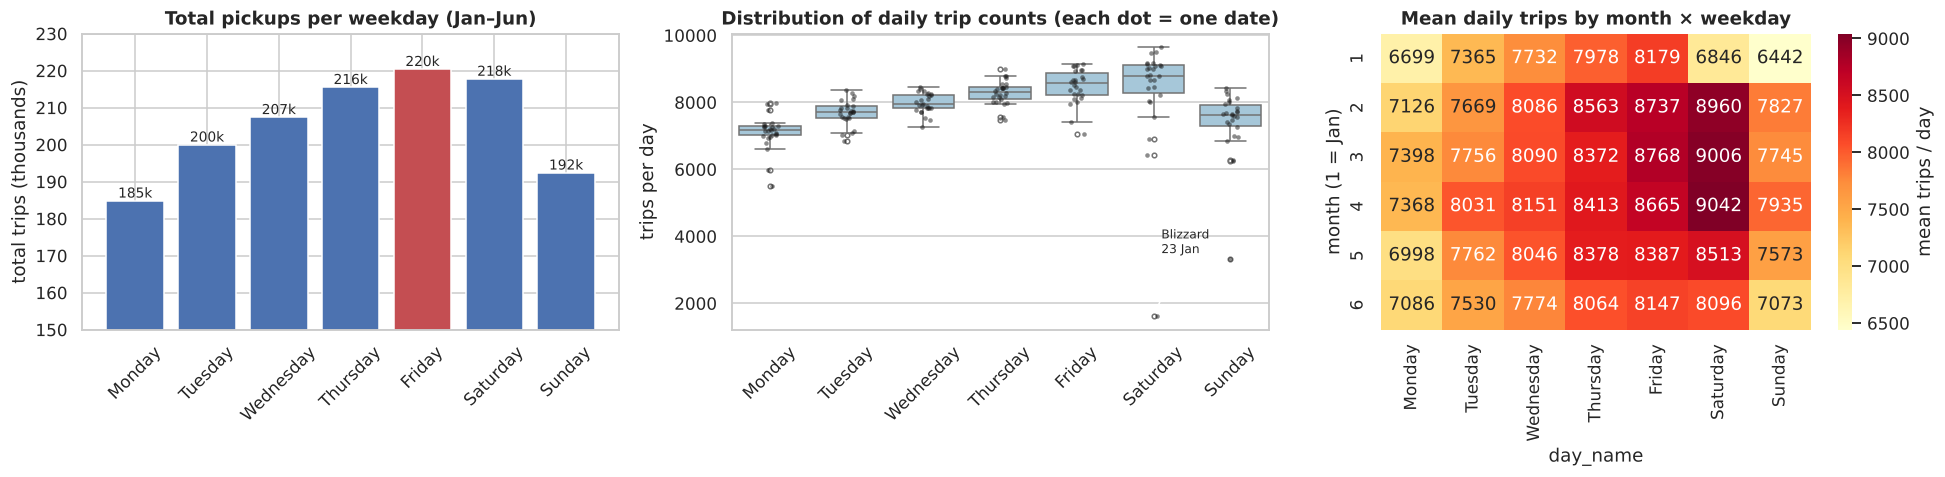

             mean    std  count
day_name                       
Monday     7154.0  467.0     25
Tuesday    7691.0  371.0     26
Wednesday  7976.0  304.0     26
Thursday   8289.0  351.0     26
Friday     8476.0  516.0     26
Saturday   8645.0  778.0     25
Sunday     7563.0  566.0     25

Top two by mean daily trips: Saturday (8645) vs Friday (8476); Welch t = 0.91, p = 0.368
Friday in the top-3 busiest weekday of the month in 6 of 6 months


In [18]:
total_by_day = feat.groupby("day_name", observed=True).size()
typical = daily[~daily.storm]                                                  # daily counts without the blizzard days
mean_by_day = typical.groupby("day_name", observed=True).trips.agg(["mean", "std", "count"])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
cols = ["#4c72b0"] * 7; cols[total_by_day.values.argmax()] = "#c44e52"
axes[0].bar(DAYS, total_by_day.values / 1e3, color=cols)
for i, v in enumerate(total_by_day.values): axes[0].text(i, v / 1e3, f"{v/1e3:.0f}k", ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(150, 230); axes[0].set_ylabel("total trips (thousands)"); axes[0].set_title("Total pickups per weekday (Jan–Jun)")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=daily, x="day_name", y="trips", ax=axes[1], color="#9ecae1", fliersize=3)
sns.stripplot(data=daily, x="day_name", y="trips", ax=axes[1], color="k", size=3, alpha=.5)
axes[1].set_title("Distribution of daily trip counts (each dot = one date)"); axes[1].set_xlabel(""); axes[1].set_ylabel("trips per day")
axes[1].tick_params(axis="x", rotation=45)
axes[1].annotate("Blizzard\n23 Jan", xy=(5, 1614), xytext=(5.1, 3500), fontsize=8, arrowprops=dict(arrowstyle="->"))

piv = daily.pivot_table(index="month", columns="day_name", values="trips", aggfunc="mean", observed=True)
sns.heatmap(piv, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[2], cbar_kws={"label": "mean trips / day"})
axes[2].set_title("Mean daily trips by month × weekday"); axes[2].set_ylabel("month (1 = Jan)")
plt.tight_layout(); savefig("q3_1_popular_day"); plt.show()

print(mean_by_day.round(0).to_string())
# Is the winner statistically distinguishable from the runner-up? (Welch t-test on daily counts, storm excluded)
top2 = mean_by_day["mean"].nlargest(2).index
a, b = (typical[typical.day_name == d].trips for d in top2)
t, p = stats.ttest_ind(a, b, equal_var=False)
print(f"\nTop two by mean daily trips: {top2[0]} ({a.mean():.0f}) vs {top2[1]} ({b.mean():.0f}); Welch t = {t:.2f}, p = {p:.3f}")
print("Friday in the top-3 busiest weekday of the month in", int((piv.rank(axis=1, ascending=False)["Friday"] <= 3).sum()), "of 6 months")

**Answer – Friday and Saturday are the two most popular days, and they are statistically tied; both clearly beat Sunday–Wednesday.**

* **Totals over the six months:** Friday is highest (220 378 pickups), then Saturday (217 740), Thursday (215 509), Wednesday (207 384),
  Tuesday (199 969), Sunday (192 396) and Monday (184 820, the quietest). Every weekday occurs 26 times, so totals are directly comparable
  (Friday vs Monday: +19 %).
* **Typical days (blizzard excluded):** removing Winter Storm Jonas (which fell on a Saturday/Sunday and cost Saturday ≈ 7 000 trips) puts **Saturday first** (≈ 8 645 trips/day) and Friday second (≈ 8 476).
  The Welch t-test on daily counts gives p = 0.37, so the Friday–Saturday difference is **not significant**: the honest answer is a tie, with Friday winning on raw totals only because of the blizzard.
  Friday is among the three busiest weekdays in all 6 months.
* **Robustness:** the box-plots show Friday's and Saturday's distributions of daily counts sit above Sunday–Wednesday (Saturday also has the largest spread).
  The month × weekday heat-map lets you check that the ordering is not driven by a single month.
* **Why:** Thursday–Saturday are the "going-out" days (dinner, bars, shows, then the ride home) on top of the regular commute; Monday and Sunday are low because there is neither a
  full leisure demand (Sunday) nor a strong start-of-week demand (Monday). The single lowest day in the data set is the blizzard itself (Sat 23 Jan, 1 614 trips) – bad weather suppresses demand far more than any weekday effect.

### 3.2 What hour of the day is the most popular on each day? [3 marks]

           peak hour  mean trips in peak hour  quietest hour  mean trips in quietest hour
Monday            18                    495.0              3                         46.0
Tuesday           18                    512.0              3                         38.0
Wednesday         19                    521.0              4                         47.0
Thursday          21                    538.0              4                         52.0
Friday            19                    538.0              4                         87.0
Saturday          23                    521.0              5                         76.0
Sunday             0                    484.0              5                         76.0


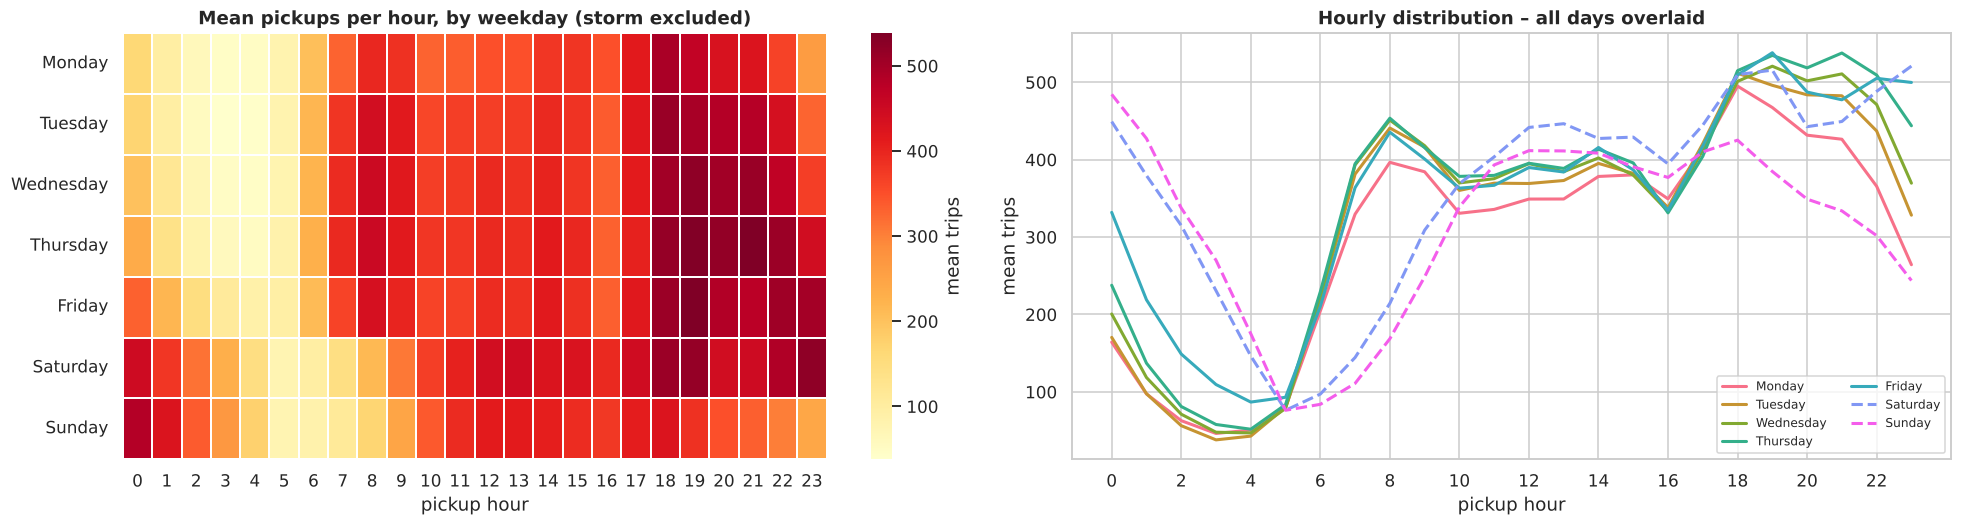

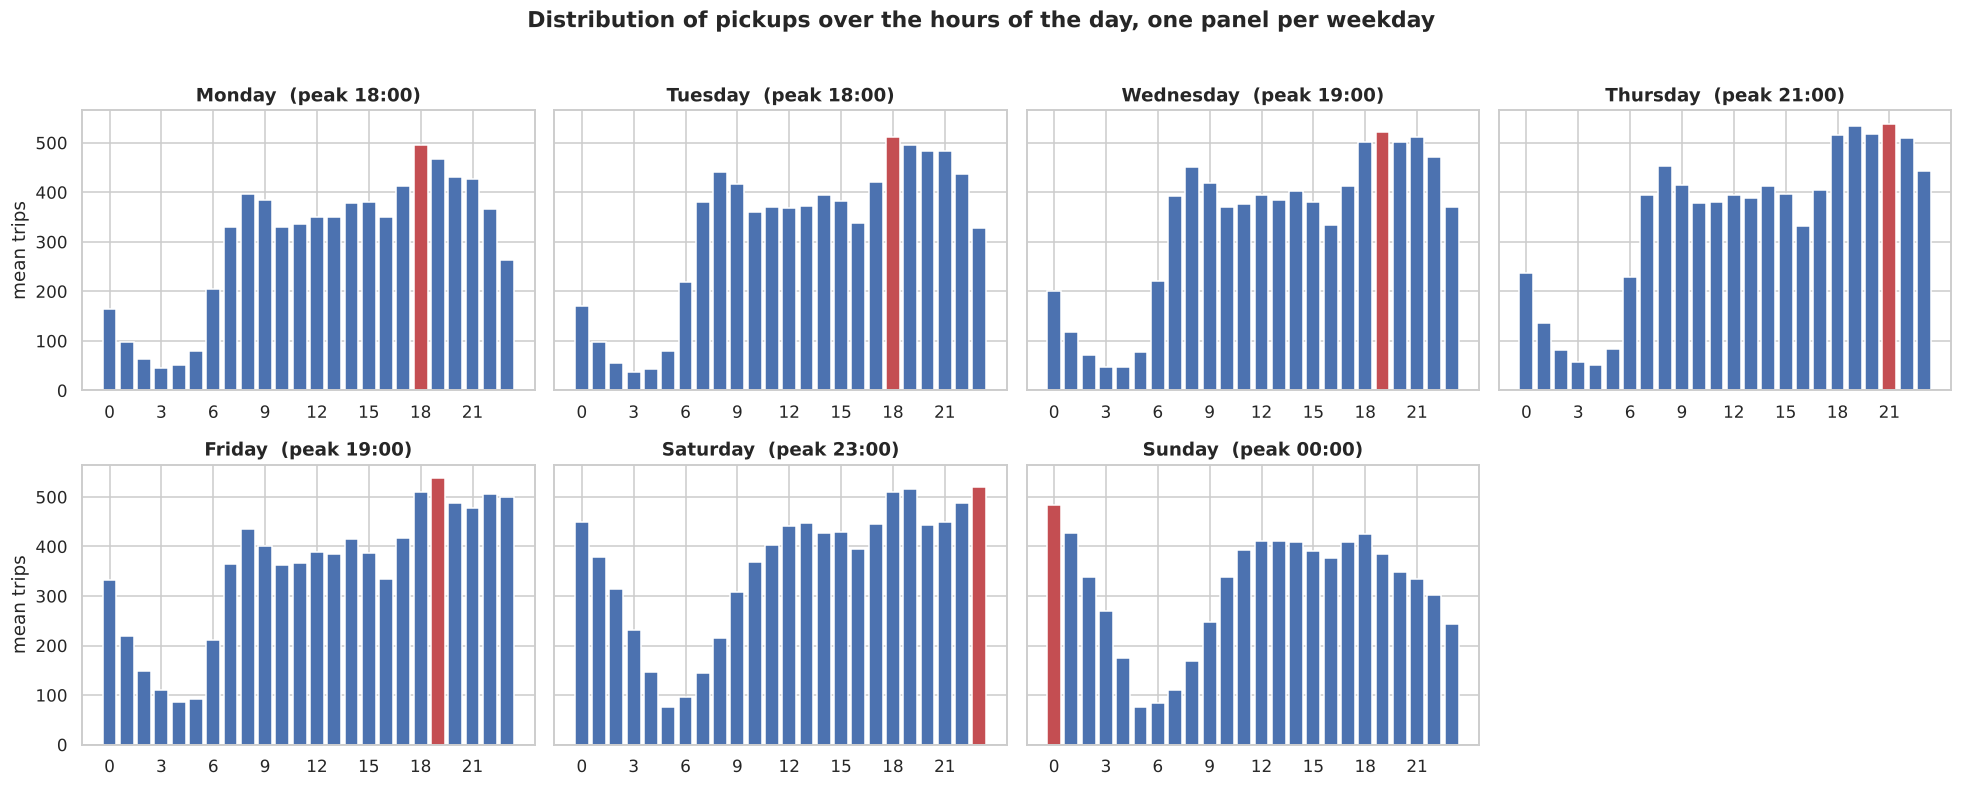

In [19]:
# average number of trips in each (weekday, hour) slot, per calendar occurrence of that weekday (storm days excluded)
hourly_t = hourly[~hourly.index.isin(STORM)]
dow_idx = hourly_t.index.dayofweek
slot = hourly_t.groupby(dow_idx).mean()                  # 7 x 24: mean trips in that hour on that weekday
slot.index = DAYS
peak = pd.DataFrame({"peak hour": slot.idxmax(axis=1),
                     "mean trips in peak hour": slot.max(axis=1).round(0),
                     "quietest hour": slot.idxmin(axis=1),
                     "mean trips in quietest hour": slot.min(axis=1).round(0)})
print(peak.to_string())

fig = plt.figure(figsize=(18, 9))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1])
ax = fig.add_subplot(gs[0, :2])
sns.heatmap(slot, cmap="YlOrRd", ax=ax, cbar_kws={"label": "mean trips"}, linewidths=.2)
ax.set_title("Mean pickups per hour, by weekday (storm excluded)"); ax.set_xlabel("pickup hour"); ax.set_ylabel("")
ax = fig.add_subplot(gs[0, 2:])
for d, c in zip(DAYS, sns.color_palette("husl", 7)):
    ax.plot(slot.columns, slot.loc[d], label=d, color=c, lw=2, ls="-" if d not in ("Saturday", "Sunday") else "--")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("pickup hour"); ax.set_ylabel("mean trips"); ax.legend(ncol=2, fontsize=8)
ax.set_title("Hourly distribution – all days overlaid")
plt.tight_layout(); savefig("q3_2_hour_heatmap_lines"); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey=True)
for a, d in zip(axes.ravel(), DAYS):
    v = slot.loc[d]
    a.bar(v.index, v.values, color=["#c44e52" if h == v.idxmax() else "#4c72b0" for h in v.index])
    a.set_title(f"{d}  (peak {v.idxmax():02d}:00)"); a.set_xticks(range(0, 24, 3))
for a in axes[:, 0]: a.set_ylabel("mean trips")
axes.ravel()[-1].axis("off")
plt.suptitle("Distribution of pickups over the hours of the day, one panel per weekday", y=1.02, fontweight="bold")
plt.tight_layout(); savefig("q3_2_hour_distribution_per_day"); plt.show()

**Observations** (peak hours from the table printed above):

| Day | Most popular hour | Quietest hour |
|---|---|---|
| Mon / Tue | 18:00 | 03:00 |
| Wed / Fri | 19:00 | 03:00 / 04:00 |
| Thu | 21:00 | 04:00 |
| Sat | 23:00 | 05:00 |
| Sun | 00:00 | 05:00 |

* **Weekdays (Mon–Fri)** share one shape: an almost empty night (minimum at 03:00–04:00), a steep rise at **06:00–08:00** (morning commute), a roughly flat plateau through the working day,
  and the maximum in the **evening, 18:00–21:00** (evening commute plus dinner and going out; on Thursday it is pushed later, to 21:00, as the week's going-out night begins).
* **Saturday and Sunday** have no morning commuter peak. Demand rises slowly through the late morning to a broad afternoon plateau, and the maximum is at **23:00 on Saturday and 00:00 on Sunday** –
  i.e. Friday night and Saturday night spilling past midnight into the next calendar day. Nights are also far busier than on weekdays: the quietest hour on Friday/Saturday/Sunday still has 76–87 pickups against 38–52 on Monday–Thursday.
* **Possible reasons:** (i) commuting (office hours, peaks around 08:00 and 18:00); (ii) dinner, theatre and bar traffic from 19:00 to midnight, with 4 a.m. bar closing time driving weekend rides home between 01:00 and 04:00;
  (iii) the dip at ≈ 16:00 followed by a jump at 17:00 on weekdays is consistent with the well-known **taxi shift change** (day drivers hand over around 16:00–17:00, so fewer meters start); (iv) between 03:00 and 05:00 almost nobody travels except airport runs and shift workers, hence the global minimum.

### 3.3 Weekdays vs weekends [2 marks]

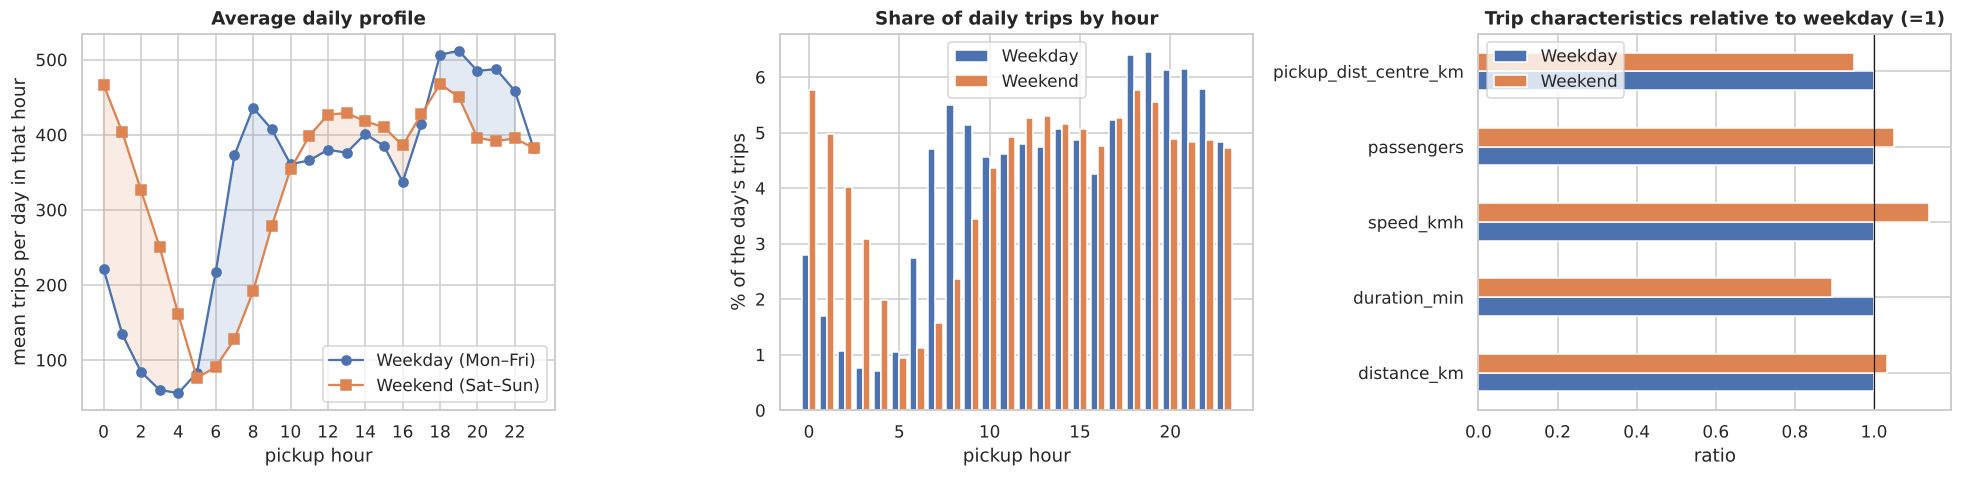

Mean trips per day: weekday = 7923, weekend = 8104
         distance_km  duration_min  speed_kmh  passengers  pickup_dist_centre_km
Weekday         3.42         14.43      13.93        1.64                   5.60
Weekend         3.54         12.91      15.86        1.72                   5.31

Share of trips between 00:00-05:00: weekday 7.0%, weekend 19.8%
Share of trips between 07:00-10:00: weekday 15.3%, weekend 7.4%
Share of trips between 18:00-22:00: weekday 25.1%, weekend 21.0%


In [20]:
wk = hourly_t.groupby(hourly_t.index.dayofweek >= 5).mean().T
wk.columns = ["Weekday (Mon–Fri)", "Weekend (Sat–Sun)"]
clean_nostorm = feat[~feat.pickup_date.isin(STORM)]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(wk.index, wk.iloc[:, 0], "-o", label=wk.columns[0]); axes[0].plot(wk.index, wk.iloc[:, 1], "-s", label=wk.columns[1])
axes[0].set_xticks(range(0, 24, 2)); axes[0].set_xlabel("pickup hour"); axes[0].set_ylabel("mean trips per day in that hour")
axes[0].set_title("Average daily profile"); axes[0].legend()
axes[0].fill_between(wk.index, wk.iloc[:, 0], wk.iloc[:, 1], where=wk.iloc[:, 1] > wk.iloc[:, 0], alpha=.15, color="C1")
axes[0].fill_between(wk.index, wk.iloc[:, 0], wk.iloc[:, 1], where=wk.iloc[:, 1] <= wk.iloc[:, 0], alpha=.15, color="C0")

share = wk / wk.sum()
axes[1].bar(share.index - .2, share.iloc[:, 0] * 100, .4, label="Weekday"); axes[1].bar(share.index + .2, share.iloc[:, 1] * 100, .4, label="Weekend")
axes[1].set_xlabel("pickup hour"); axes[1].set_ylabel("% of the day's trips"); axes[1].set_title("Share of daily trips by hour"); axes[1].legend()

comp = clean_nostorm.groupby("is_weekend").agg(distance_km=("distance_km", "mean"), duration_min=("duration_min", "mean"),
        speed_kmh=("speed_kmh", "mean"), passengers=("passenger_count", "mean"), pickup_dist_centre_km=("pickup_dist_centre_km", "mean"))
comp.index = ["Weekday", "Weekend"]
(comp / comp.loc["Weekday"]).T.plot.barh(ax=axes[2]); axes[2].axvline(1, color="k", lw=.8)
axes[2].set_title("Trip characteristics relative to weekday (=1)"); axes[2].set_xlabel("ratio")
plt.tight_layout(); savefig("q3_3_weekday_vs_weekend"); plt.show()

print("Mean trips per day: weekday = %.0f, weekend = %.0f" % (daily[~daily.storm & (daily.dow < 5)].trips.mean(), daily[~daily.storm & (daily.dow >= 5)].trips.mean()))
print(comp.round(2).to_string())
print("\nShare of trips between 00:00-05:00: weekday %.1f%%, weekend %.1f%%" % tuple(share.iloc[0:5].sum() * 100))
print("Share of trips between 07:00-10:00: weekday %.1f%%, weekend %.1f%%" % tuple(share.iloc[7:10].sum() * 100))
print("Share of trips between 18:00-22:00: weekday %.1f%%, weekend %.1f%%" % tuple(share.iloc[18:22].sum() * 100))

**Differences between weekdays and weekends** (storm excluded):

1. **Total volume is similar** (≈ 7 900 trips on a weekday vs ≈ 8 100 on a weekend day), but it is *distributed differently* over the day.
2. **Weekday shape = commuter-driven:** a sharp 07:00–09:00 peak (15.3 % of weekday trips between 07:00 and 10:00, only 7.4 % at weekends) and a larger 18:00–22:00 evening share (25.1 % vs 21.0 %).
3. **Weekend shape = leisure-driven:** no morning rush; demand builds slowly from late morning to a broad plateau of
   ≈ 13:00–19:00 (shopping, brunch, tourism, events); the share of trips between 00:00 and 05:00 is ≈ 2.8× higher on weekends (19.8 % vs 7.0 %; these are the Friday- and Saturday-night
   outings returning home), and the weekend curve is also above the weekday curve from roughly 11:00 to 17:00.
4. **Trip characteristics:** weekend trips are **faster** (≈ 15.9 vs 13.9 km/h) because the streets are less congested,
   **shorter in time** (≈ 12.9 vs 14.4 min) for a similar distance (3.5 vs 3.4 km), carry slightly **more passengers** (1.72 vs 1.64 – groups/families rather than solo business travellers)
   and start slightly closer to the centre (5.3 vs 5.6 km). The weekend speed advantage holds between 05:00 and 19:00; at night (00:00–04:00 and 20:00–23:00) weekend streets are no faster, because they are busy with nightlife traffic.
5. **What accounts for it:** the working week – commute, congestion and business trips – versus a social calendar of nightlife, brunch, tourism and events.

### 3.4 Holidays [5 marks]

2016 dates (the correct dates for the relevant year; all fall inside Jan–Jun 2016):

| Holiday | 2016 date | Weekday |
|---|---|---|
| Martin Luther King Jr. Day (3rd Monday of Jan) | 18 Jan | Monday |
| Valentine's Day | 14 Feb | Sunday |
| St Patrick's Day | 17 Mar | Thursday |
| Easter Sunday | 27 Mar | Sunday |
| Memorial Day (last Monday of May) | 30 May | Monday |

**Method:** a holiday cannot be judged against the average day – it must be compared with *ordinary days of the same weekday*.
For each holiday we build a baseline of all other same-weekday dates (excluding the other holidays and the blizzard days), then compare (a) the daily total,
as a ratio and a z-score against the baseline's day-to-day variation, (b) the hour-by-hour profile, and (c) speed and distance.

In [21]:
HOLIDAYS = {"Martin Luther King Day": "2016-01-18", "Valentine's Day": "2016-02-14", "St Patrick's Day": "2016-03-17",
            "Easter Sunday": "2016-03-27", "Memorial Day": "2016-05-30"}
HOLIDAYS = {k: pd.Timestamp(v) for k, v in HOLIDAYS.items()}
EXCLUDE = set(HOLIDAYS.values()) | set(STORM)
dow_all = feat.pickup_datetime.dt.dayofweek

rows = []
fig_data = {}
for name, d in HOLIDAYS.items():
    dw = d.dayofweek
    base_days = daily[(daily.dow == dw) & (~daily.index.isin(EXCLUDE))]
    base_h = hourly[(hourly.index.dayofweek == dw) & (~hourly.index.isin(EXCLUDE))]
    h_trips = feat[feat.pickup_date == d]
    b_trips = feat[(dow_all == dw) & (~feat.pickup_date.isin(EXCLUDE))]
    rows.append({"holiday": name, "date": d.date(), "weekday": d.day_name(),
                 "trips": int(daily.loc[d, "trips"]), "baseline_mean": round(base_days.trips.mean()),
                 "ratio": round(daily.loc[d, "trips"] / base_days.trips.mean(), 3),
                 "z_score": round((daily.loc[d, "trips"] - base_days.trips.mean()) / base_days.trips.std(), 2),
                 "peak_hour": int(hourly.loc[d].idxmax()), "baseline_peak_hour": int(base_h.mean().idxmax()),
                 "speed_kmh": round(h_trips.speed_kmh.mean(), 1), "baseline_speed": round(b_trips.speed_kmh.mean(), 1),
                 "dist_km": round(h_trips.distance_km.mean(), 2), "baseline_dist": round(b_trips.distance_km.mean(), 2),
                 "n_baseline_days": len(base_days)})
    fig_data[name] = (base_h, hourly.loc[d])
hol_tbl = pd.DataFrame(rows).set_index("holiday")
hol_tbl

,date,weekday,trips,baseline_mean,ratio,z_score,peak_hour,baseline_peak_hour,speed_kmh,baseline_speed,dist_km,baseline_dist,n_baseline_days
holiday,,,,,,,,,,,,,
Martin Luther King Day,2016-01-18,Monday,7037,7231,0.973,-0.60,18,18,16.8,15.0,3.50,3.55,23
Valentine's Day,2016-02-14,Sunday,8342,7542,1.106,1.42,17,0,15.8,16.8,3.31,3.77,23
St Patrick's Day,2016-03-17,Thursday,8147,8294,0.982,-0.41,20,21,13.9,13.5,3.52,3.43,25
Easter Sunday,2016-03-27,Sunday,7264,7542,0.963,-0.49,0,0,17.5,16.8,3.82,3.77,23
Memorial Day,2016-05-30,Monday,5491,7231,0.759,-5.35,16,18,19.1,15.0,4.30,3.55,23


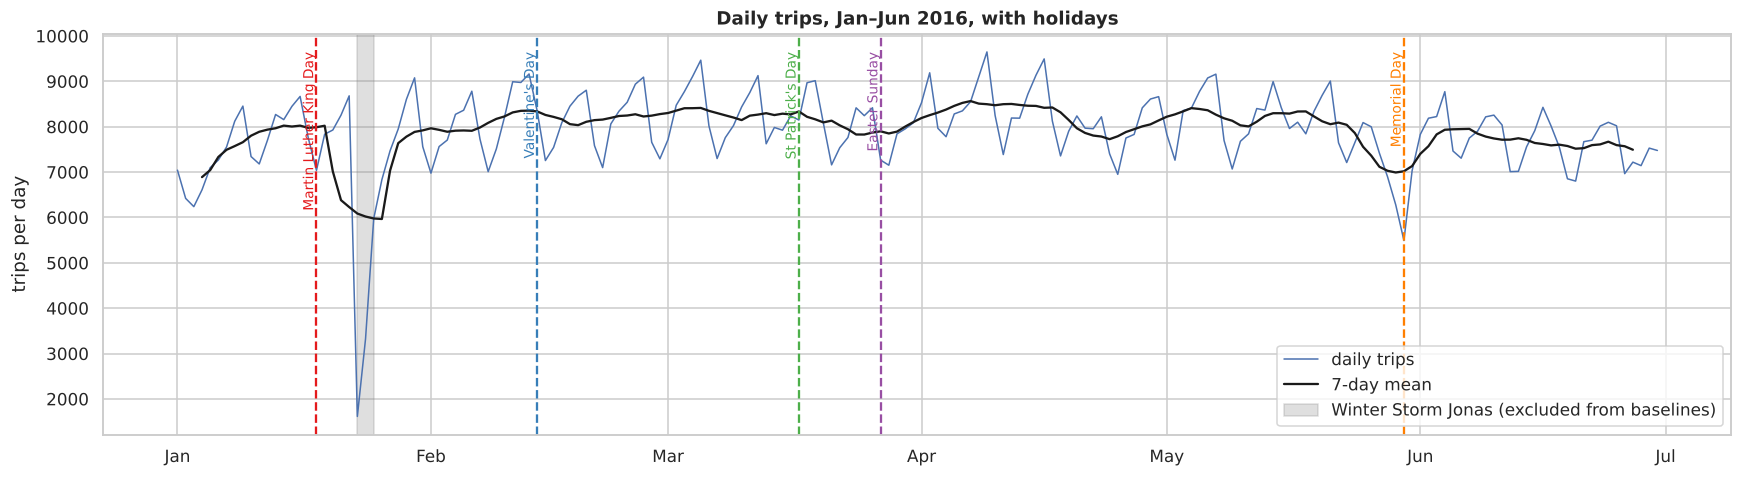

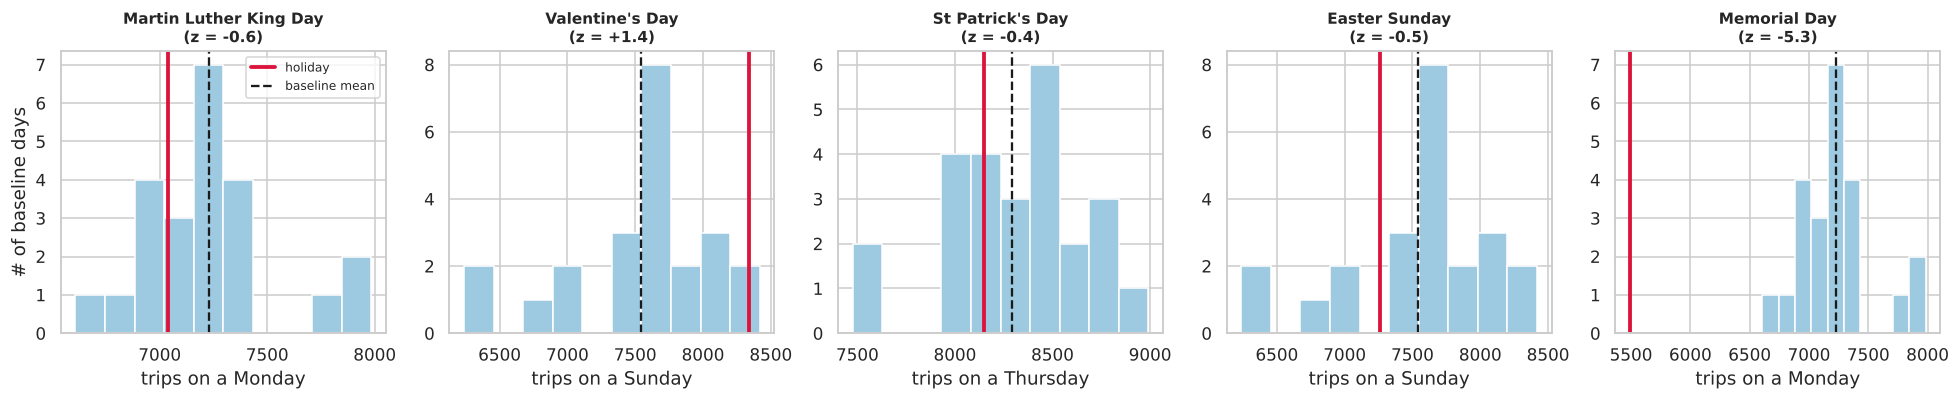

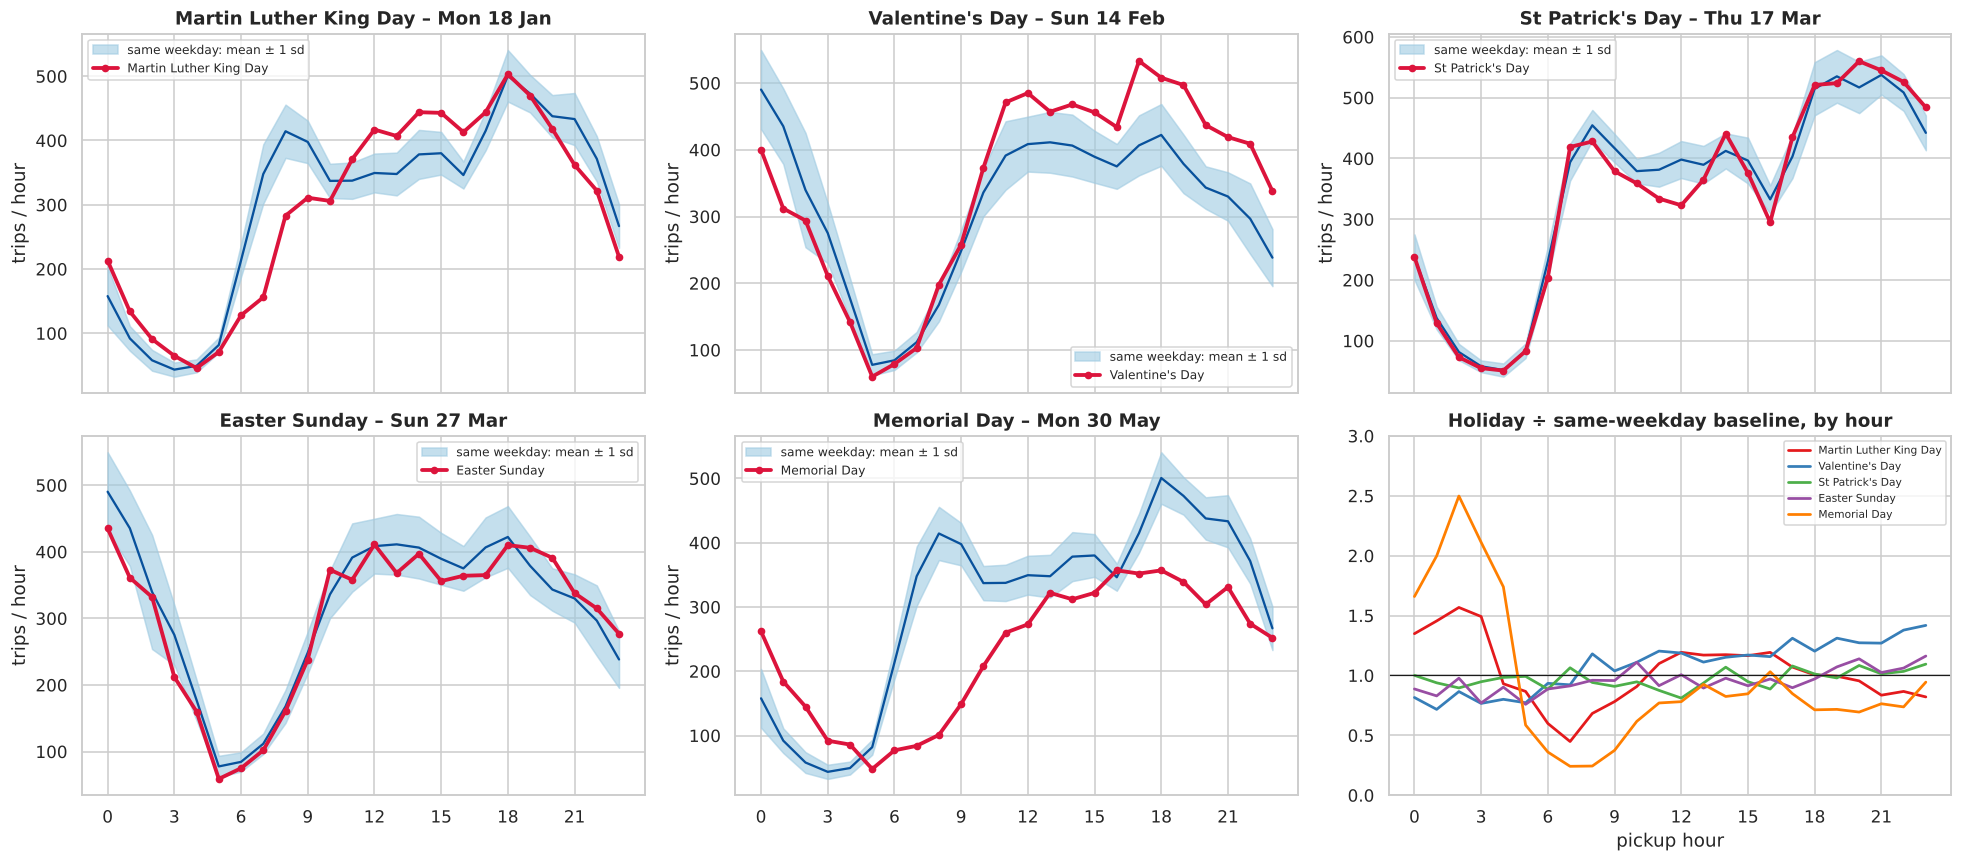

In [22]:
# (a) the whole six months with holidays marked
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(daily.index, daily.trips, color="#4c72b0", lw=1, label="daily trips")
ax.plot(daily.index, daily.trips.rolling(7, center=True).mean(), color="k", lw=1.5, label="7-day mean")
for (name, d), c in zip(HOLIDAYS.items(), sns.color_palette("Set1", 5)):
    ax.axvline(d, color=c, ls="--"); ax.annotate(name, (d, daily.trips.max() * 1.0), rotation=90, color=c, va="top", ha="right", fontsize=9)
ax.axvspan(STORM[0], STORM[-1], color="grey", alpha=.25, label="Winter Storm Jonas (excluded from baselines)")
ax.set_ylabel("trips per day"); ax.set_title("Daily trips, Jan–Jun 2016, with holidays"); ax.legend(loc="lower right")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b")); plt.tight_layout(); savefig("q3_4_timeline_holidays"); plt.show()

# (b) daily total versus the same-weekday baseline
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8), sharey=False)
for a, (name, d) in zip(axes, HOLIDAYS.items()):
    b = daily[(daily.dow == d.dayofweek) & (~daily.index.isin(EXCLUDE))].trips
    a.hist(b, bins=10, color="#9ecae1", edgecolor="w"); a.axvline(daily.loc[d, "trips"], color="crimson", lw=2.5, label="holiday")
    a.axvline(b.mean(), color="k", ls="--", label="baseline mean")
    a.set_title(f"{name}\n(z = {hol_tbl.loc[name, 'z_score']:+.1f})", fontsize=10); a.set_xlabel(f"trips on a {d.day_name()}")
axes[0].legend(fontsize=8); axes[0].set_ylabel("# of baseline days")
plt.tight_layout(); savefig("q3_4_holiday_totals"); plt.show()

# (c) hourly profile of each holiday versus the same-weekday baseline (mean ± 1 sd)
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=True)
for a, (name, (base_h, hol)) in zip(axes.ravel(), fig_data.items()):
    m, s = base_h.mean(), base_h.std()
    a.fill_between(m.index, m - s, m + s, color="#9ecae1", alpha=.6, label="same weekday: mean ± 1 sd")
    a.plot(m.index, m, color="#08519c", lw=1.5); a.plot(hol.index, hol.values, color="crimson", lw=2.5, marker="o", ms=4, label=name)
    a.set_title(f"{name} – {HOLIDAYS[name].strftime('%a %d %b')}"); a.set_xticks(range(0, 24, 3)); a.legend(fontsize=8); a.set_ylabel("trips / hour")
ax = axes.ravel()[-1]
for (name, (base_h, hol)), c in zip(fig_data.items(), sns.color_palette("Set1", 5)):
    ax.plot(hol.index, hol.values / base_h.mean().values, color=c, label=name, lw=1.8)
ax.axhline(1, color="k", lw=.8); ax.set_title("Holiday ÷ same-weekday baseline, by hour"); ax.set_ylim(0, 3); ax.legend(fontsize=7); ax.set_xlabel("pickup hour")
plt.tight_layout(); savefig("q3_4_holiday_hourly"); plt.show()

**Do patterns change on holidays?** (see the table, the totals histograms and the hourly overlays above)

* **Memorial Day (Mon 30 May)** is the only holiday with a clear, statistically unusual change in the daily total: 5 491 trips, only
  **≈ 76 %** of a normal Monday and about −5.4 standard deviations from the baseline. The hourly plot shows the morning commute almost vanishing (07:00 at only ≈ 24 % of a normal Monday),
  the peak hour moves from 18:00 to 16:00, and after-midnight trips are much higher than normal (≈ 2.5× at 02:00 – the tail of Sunday night's long-weekend outings).
  Trips are **faster and longer** (19.1 vs 15.0 km/h and 4.3 vs 3.55 km): the roads are empty because the offices are closed, and a long-weekend departure from the city (including airport trips) is a plausible reason for the longer distances.
* **Martin Luther King Day (Mon 18 Jan)** is a federal holiday, but the total is within normal range (≈ 97 % of a Monday, z ≈ −0.6). The shape does change: the morning commute is
  much weaker (≈ 45 % of normal at 07:00), speed is higher (16.8 vs 15.0 km/h), and the small hours are busier (≈ 1.6× at 02:00), consistent with a long weekend in which people go out on Sunday night.
* **Valentine's Day (Sun 14 Feb)** has the highest total relative to its baseline (≈ +10.6 % on an ordinary Sunday), although at z ≈ +1.4 this is a modest rather than decisive increase. The shape changes more than the volume:
  the peak hour is 17:00 instead of the small hours (00:00) of an ordinary Sunday, i.e. demand shifts into the early evening (dinner reservations) and the after-midnight spill-over from Saturday night is weaker (≈ 0.72× at 01:00);
  late evening is higher (≈ 1.4× at 23:00). Trips are shorter (3.3 vs 3.8 km) and slower (15.8 vs 16.8 km/h): short hops in busy central areas.
* **St Patrick's Day (Thu 17 Mar)** has essentially the normal total (98 % of a Thursday, z ≈ −0.4) and the same overall shape; the evening peak is an hour earlier (20:00 vs 21:00). The largest deviations are a dip
  at midday (≈ 0.81× at 12:00, plausibly from the 5th Avenue parade closing streets in Midtown) and slightly higher late-evening demand (≈ 1.09× at 23:00). Speed (13.9 vs 13.5 km/h) and distance (3.5 vs 3.4 km) are effectively unchanged.
* **Easter Sunday (27 Mar)** is the closest to a normal day: 96 % of a normal Sunday (z ≈ −0.5), same peak hour (00:00), only slightly higher speed (17.5 vs 16.8 km/h); the largest hourly deviations are
  ≈ 0.76× at 05:00 and ≈ 1.16× at 23:00. Easter is a family/religious day with no large city-wide event, and taxi use is hardly affected.

**Overall:** only Memorial Day produces a daily total outside the usual day-to-day variation; for the other four the *total* is within about 1.5 standard deviations of an ordinary same-weekday, but the
*hourly shape* shifts (weaker commute peaks on the two Monday holidays, a changed evening peak on Valentine's Day). Holiday effects are therefore mostly **redistributions of demand across hours** rather than changes in volume —
with the exception of the long-weekend Monday where volume truly falls. (Caveat: we have a single occurrence of each holiday, so the "baseline" comparison is the best available but a one-off event such as weather could still play a role.)

### 3.5 How does average speed change through the day? [2 marks]

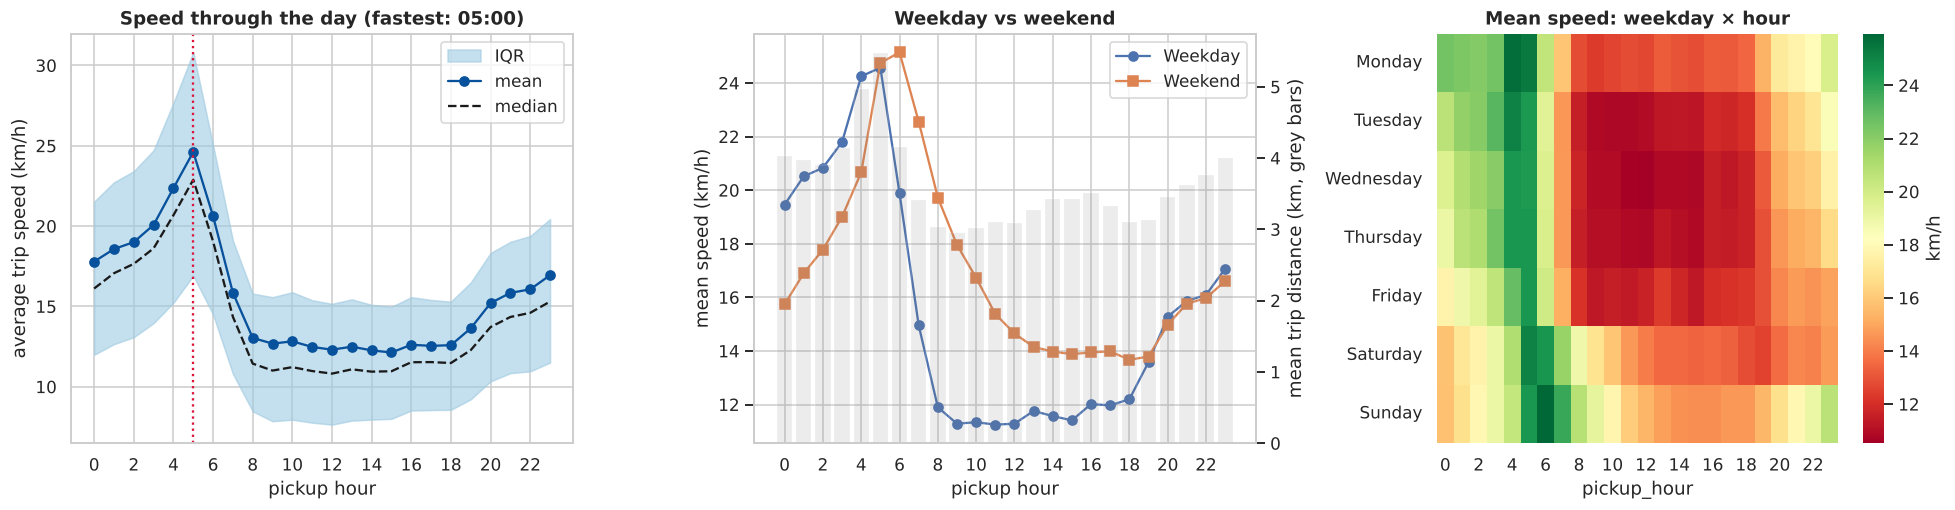

Fastest hour: 5 → 24.6 km/h;   slowest hour: 15 → 12.1 km/h


Mean speed 08:00-18:00 (working day): 12.5 km/h;  00:00-05:00: 19.5 km/h
Mean distance at 05:00 / 15:00: 5.47 / 3.43 km


pickup_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
mean,17.8,18.6,19.0,20.1,22.4,24.6,20.6,15.8,13.0,12.7,...,12.3,12.1,12.6,12.5,12.6,13.6,15.2,15.8,16.1,16.9
50%,16.1,17.1,17.6,18.6,20.7,22.9,19.0,14.3,11.4,11.0,...,10.9,11.0,11.5,11.5,11.5,12.3,13.7,14.3,14.6,15.3


In [23]:
sp = clean_nostorm.groupby("pickup_hour").speed_kmh.describe(percentiles=[.25, .5, .75])
sp_wk = clean_nostorm.groupby(["is_weekend", "pickup_hour"]).speed_kmh.mean().unstack(0); sp_wk.columns = ["Weekday", "Weekend"]
dist_h = clean_nostorm.groupby("pickup_hour").distance_km.mean()
sp_dh = clean_nostorm.pivot_table(index="day_name", columns="pickup_hour", values="speed_kmh", aggfunc="mean", observed=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.fill_between(sp.index, sp["25%"], sp["75%"], color="#9ecae1", alpha=.6, label="IQR")
ax.plot(sp.index, sp["mean"], "-o", color="#08519c", label="mean"); ax.plot(sp.index, sp["50%"], "--", color="k", label="median")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("pickup hour"); ax.set_ylabel("average trip speed (km/h)"); ax.legend()
ax.axvline(sp["mean"].idxmax(), color="crimson", ls=":"); ax.set_title(f"Speed through the day (fastest: {sp['mean'].idxmax():02d}:00)")
ax = axes[1]
ax.plot(sp_wk.index, sp_wk.Weekday, "-o", label="Weekday"); ax.plot(sp_wk.index, sp_wk.Weekend, "-s", label="Weekend")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("pickup hour"); ax.set_ylabel("mean speed (km/h)"); ax.legend(); ax.set_title("Weekday vs weekend")
ax2 = ax.twinx(); ax2.bar(dist_h.index, dist_h.values, alpha=.15, color="grey"); ax2.set_ylabel("mean trip distance (km, grey bars)"); ax2.grid(False)
sns.heatmap(sp_dh, cmap="RdYlGn", ax=axes[2], cbar_kws={"label": "km/h"}); axes[2].set_title("Mean speed: weekday × hour"); axes[2].set_ylabel("")
plt.tight_layout(); savefig("q3_5_speed_by_hour"); plt.show()

print("Fastest hour:", int(sp["mean"].idxmax()), "→", round(sp["mean"].max(), 1), "km/h;   slowest hour:", int(sp["mean"].idxmin()), "→", round(sp["mean"].min(), 1), "km/h")
print("Mean speed 08:00-18:00 (working day):", round(clean_nostorm[clean_nostorm.pickup_hour.between(8, 18)].speed_kmh.mean(), 1),
      "km/h;  00:00-05:00:", round(clean_nostorm[clean_nostorm.pickup_hour <= 5].speed_kmh.mean(), 1), "km/h")
print("Mean distance at 05:00 / 15:00:", round(dist_h[5], 2), "/", round(dist_h[15], 2), "km")
sp[["mean", "50%"]].round(1).T

**Answer – trips are fastest in the early morning, around 05:00 (≈ 24–25 km/h on average),** and slowest in the middle of the working day.

* **Night (00:00–05:00):** speed climbs steadily from ≈ 18 km/h at midnight to the daily maximum of ≈ 24.6 km/h at 05:00 – the streets are nearly empty and traffic lights are the only constraint. The 05:00 peak is also partly a
  *trip-mix* effect: at that hour the mean trip is much longer (airport runs and highway/bridge trips), and longer trips spend more time at highway speed, so their average speed is higher.
* **Sharp drop at 06:00–08:00:** as the morning rush begins, speed falls from ≈ 24.6 km/h (05:00) to ≈ 13 km/h at 08:00 – the biggest change in the day.
* **Daytime (08:00–18:00):** a flat, congested plateau of ≈ 12–13 km/h (slowest around 12:00–15:00 at ≈ 12.1–12.3 km/h): Manhattan's grid, deliveries, pedestrians and turning traffic dominate and are present all day, not only at the "rush hours".
  The weekday × hour heat-map shows the same slow band between 08:00 and 18:00 on every day, and the weekday/weekend plot shows weekends are faster from 05:00 to 19:00 but not at night.
* **Evening (19:00–23:00):** speed recovers progressively (13.6 → 16.9 km/h) as commuters go home.
* **Caveat:** speed here is *haversine distance ÷ duration*, so it understates the true road speed (real routes are ≈ 1.3× longer than the straight line, see the Manhattan/straight-line ratio of 1.33 in Q2, so true speeds are roughly a quarter higher), but the *pattern* over the day is unaffected.

### Summary of Section 3

| Q | Finding |
|---|---|
| 3.1 | Friday leads on raw totals (220 378) but Saturday leads once the blizzard is removed (≈ 8 645 vs 8 476 per day); the difference is not significant (p = 0.37) – a tie. Monday is least busy. |
| 3.2 | Weekday peak at 18:00–19:00 with a morning commute bump; weekend profile has no morning peak and a busy night (00:00–03:00). Dip/jump at 16:00/17:00 is the taxi shift change. |
| 3.3 | Same total volume, different shape: commuter-driven weekdays vs leisure/night-driven weekends; weekend trips are faster and carry more passengers. |
| 3.4 | Only Memorial Day changes the daily volume markedly (−24 %); other holidays reshape *when* trips happen (weaker commute peaks, earlier/later evening peaks) more than *how many*. |
| 3.5 | Fastest at ≈ 05:00 (≈ 24.6 km/h), slowest through the working day (≈ 12 km/h), steady recovery in the evening. |

---
## 4. Location clusters [12 marks]
*(to be completed)*

4.1 Heatmaps (weekday/weekend, morning/evening) · 4.2 DBSCAN hotspots (Fri 23:00–Sat 02:00, Thu 17:00–20:00)

---
## 5. Airports [9 marks]
*(to be completed)*

Empire State Building → JFK and → Newark: travel time by time of day, with a justified radius.

---
## 6. Dimensionality reduction [22 marks]
*(to be completed)*

6.1 Feature matrix · 6.2 PCA · 6.3 t-SNE · 6.4 UMAP · 6.5 Clustering & cluster profiles · 6.6 Comparison & ARI